   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891
Dataset shape: (30, 2)

First five rows:
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes

Statistical summary:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000

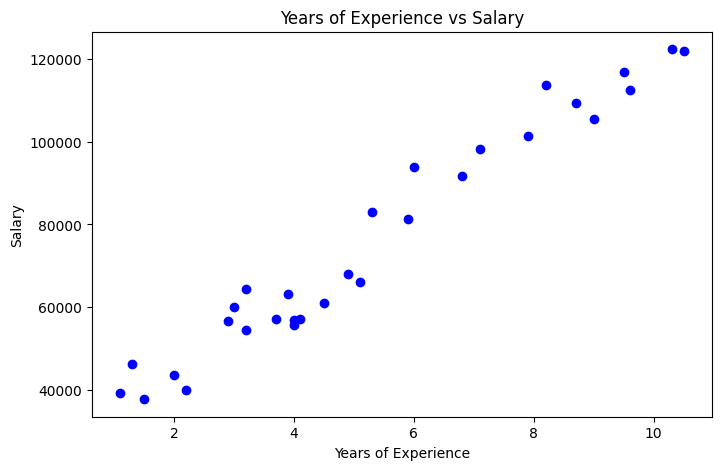


Input feature:
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2

Target variable:
0    39343
1    46205
2    37731
3    43525
4    39891
Name: Salary, dtype: int64

Training samples: 24
Testing samples: 6

Linear Regression model trained successfully!

Regression Equation:
Salary = 9423.82 * YearsExperience + 25321.58

Actual Salaries:
[112635, 67938, 113812, 83088, 64445, 57189]

Predicted Salaries:
[115790.21  71498.28 102596.87  75267.8   55477.79  60189.7 ]

Model Evaluation:
R2 Score: 0.9024
RMSE: 7059.04
MAE: 6286.45


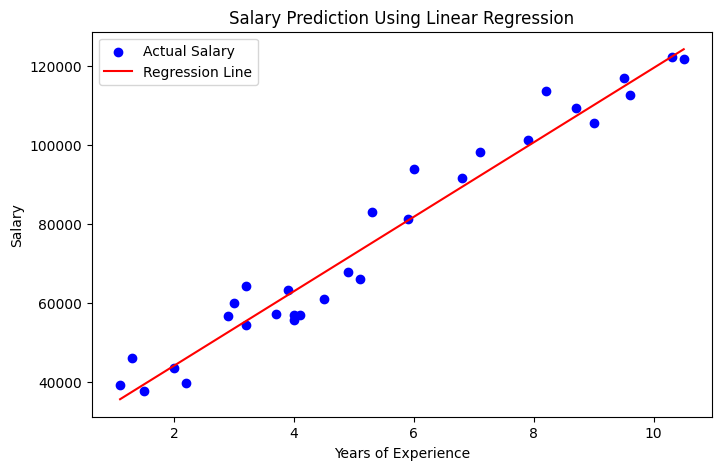

In [ ]:

# Q12: Salary Estimation Using Linear Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load the dataset
# Dataset should contain YearsExperience and Salary columns
df = pd.read_csv("/content/Salary Data - Salary Data.csv")


print(df.head())

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

# 2. Check missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 3. Remove duplicates and missing values
df.drop_duplicates(inplace=True)
df.dropna(subset=["YearsExperience", "Salary"], inplace=True)



# 4. Visualize experience vs salary
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsExperience"], df["Salary"], color="blue")
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

# 5. Select input and target variables
X = df[["YearsExperience"]]
y = df["Salary"]

print("\nInput feature:")
print(X.head())

print("\nTarget variable:")
print(y.head())

# 6. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 7. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")

# 8. Display regression equation
slope = model.coef_[0]
intercept = model.intercept_
#  y= mx +c
print("\nRegression Equation:")
print("Salary =", round(slope, 2), "* YearsExperience +", round(intercept, 2))

# 9. Predict salary for test data
y_pred = model.predict(X_test)

print("\nActual Salaries:")
print(y_test.to_list())

print("\nPredicted Salaries:")
print(np.round(y_pred, 2))

# 10. Evaluate the model
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("\nModel Evaluation:")
print("R2 Score:", round(r2, 4))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))

# 11. Plot actual data and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="blue", label="Actual Salary")

X_line = pd.DataFrame({
    "YearsExperience": np.linspace(
        X["YearsExperience"].min(),
        X["YearsExperience"].max(),
        100
    )
})

y_line = model.predict(X_line)

plt.plot(X_line["YearsExperience"], y_line, color="red",
         label="Regression Line")

plt.title("Salary Prediction Using Linear Regression")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

# 12. Predict salary for user-entered experience
experience = float(input("\nEnter years of experience: "))

new_data = pd.DataFrame({
    "YearsExperience": [experience]
})

predicted_salary = model.predict(new_data)

print("Predicted Salary:", round(predicted_salary[0], 2))
